# Subjectivity Mining — Assignment 5
## Group 9 — Helian: BERT probabilities + soft voting

Equal-weight probability averaging of BERT, HateBERT and fBERT on the OLID test set. Both in-domain (OLID training) and cross-domain (HASOC training) settings are evaluated. 
The BERT probability files were generated from retrained BERT models; HateBERT and fBERT probabilities come from the saved A4 outputs.

## 1. Load and align the six probability files

In [16]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    confusion_matrix, ConfusionMatrixDisplay,
)


files = {
    "bert_in": "bert_probs_in_domain.csv",
    "bert_cross": "bert_probs_cross_domain.csv",
    "hatebert_in": "results_hatebert_in_domain.csv",
    "hatebert_cross": "results_hatebert_cross_domain.csv",
    "fbert_in": "results_fbert_in_domain.csv",
    "fbert_cross": "results_fbert_cross_domain.csv",
}
data = {}
for name, filename in files.items():
    path = Path(filename)
    if not path.is_file():
        raise FileNotFoundError(f"Missing {path.resolve()}")
    frame = pd.read_csv(path)
    needed = {"id", "text", "labels", "probability_offensive"}
    assert needed.issubset(frame.columns), f"Missing columns in {filename}: {needed - set(frame.columns)}"
    assert len(frame) == 860 and frame["id"].is_unique, f"Unexpected rows or duplicate IDs: {filename}"
    assert frame["labels"].isin([0, 1]).all(), filename
    assert frame["probability_offensive"].notna().all() and frame["probability_offensive"].between(0, 1).all(), filename
    data[name] = frame
    print(name, frame.shape)


bert_in (860, 5)
bert_cross (860, 5)
hatebert_in (860, 8)
hatebert_cross (860, 8)
fbert_in (860, 8)
fbert_cross (860, 8)


## 2. Common evaluation function

In [20]:
def evaluate_predictions(y_true, y_pred, model_name, setting, show_matrix=True):
    macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0
    )
    p, r, f1, support = precision_recall_fscore_support(
        y_true, y_pred, labels=[0, 1], zero_division=0
    )
    summary = pd.DataFrame([{
        "model": model_name, "setting": setting,
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_precision": macro_p, "macro_recall": macro_r, "macro_f1": macro_f1,
        "precision_0": p[0], "recall_0": r[0], "f1_0": f1[0], "support_0": support[0],
        "precision_1": p[1], "recall_1": r[1], "f1_1": f1[1], "support_1": support[1],
    }])
    if show_matrix:
        cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
        disp = ConfusionMatrixDisplay(cm, display_labels=["Non-offensive (0)", "Offensive (1)"])
        disp.plot(values_format="d")
        plt.title(f"{model_name} — {setting}")
        plt.tight_layout()
        plt.show()
    return summary


## 3. Verify sample alignment and probabilities

In [25]:
def align_predictions(suffix):
    columns = ["id", "text", "labels", "probability_offensive"]
    result = data[f"bert_{suffix}"][columns].rename(columns={"probability_offensive": "bert_prob"}).copy()
    for model in ("hatebert", "fbert"):
        other = data[f"{model}_{suffix}"][columns].rename(
            columns={"probability_offensive": f"{model}_prob"}
        )
        result = result.merge(other, on=["id", "text", "labels"], how="inner", validate="one_to_one")
    assert len(result) == 860, f"Sample mismatch in {suffix}: {len(result)} matched"
    return result

aligned_in = align_predictions("in")
aligned_cross = align_predictions("cross")
assert aligned_in[["id", "text", "labels"]].equals(aligned_cross[["id", "text", "labels"]])
print("Aligned in-domain:", aligned_in.shape)
print("Aligned cross-domain:", aligned_cross.shape)
display(aligned_in.head())


Aligned in-domain: (860, 6)
Aligned cross-domain: (860, 6)


,id,text,labels,bert_prob,hatebert_prob,fbert_prob
0,15923,#WhoIsQ #WheresTheServer #DumpNike #DECLASFISA...,1,0.259567,0.886862,0.947962
1,27014,"#ConstitutionDay is revered by Conservatives, ...",0,0.902438,0.108708,0.090735
2,30530,#FOXNews #NRA #MAGA #POTUS #TRUMP #2ndAmendmen...,0,0.028571,0.116312,0.106505
3,13876,#Watching #Boomer getting the news that she is...,0,0.007681,0.012674,0.004682
4,60133,#NoPasaran: Unity demo to oppose the far-right...,1,0.225118,0.016689,0.017849


## 4. Soft voting
For each example, average the three models’ probabilities of the offensive class. Predict class 1 when the mean probability is at least 0.5.

In [29]:
def soft_voting(frame):
    result = frame.copy()
    result["probability_offensive"] = result[["bert_prob", "hatebert_prob", "fbert_prob"]].mean(axis=1)
    result["prediction"] = (result["probability_offensive"] >= 0.5).astype(int)
    result["correct"] = result["labels"] == result["prediction"]
    return result

soft_in = soft_voting(aligned_in)
soft_cross = soft_voting(aligned_cross)
print("In-domain predictions:\n", soft_in["prediction"].value_counts().sort_index())
print("Cross-domain predictions:\n", soft_cross["prediction"].value_counts().sort_index())
display(soft_in.head())


In-domain predictions:
 prediction
0    622
1    238
Name: count, dtype: int64
Cross-domain predictions:
 prediction
0    661
1    199
Name: count, dtype: int64


,id,text,labels,bert_prob,hatebert_prob,fbert_prob,probability_offensive,prediction,correct
0,15923,#WhoIsQ #WheresTheServer #DumpNike #DECLASFISA...,1,0.259567,0.886862,0.947962,0.698131,1,True
1,27014,"#ConstitutionDay is revered by Conservatives, ...",0,0.902438,0.108708,0.090735,0.367294,0,True
2,30530,#FOXNews #NRA #MAGA #POTUS #TRUMP #2ndAmendmen...,0,0.028571,0.116312,0.106505,0.083796,0,True
3,13876,#Watching #Boomer getting the news that she is...,0,0.007681,0.012674,0.004682,0.008345,0,True
4,60133,#NoPasaran: Unity demo to oppose the far-right...,1,0.225118,0.016689,0.017849,0.086552,0,False


## 5. In-domain results

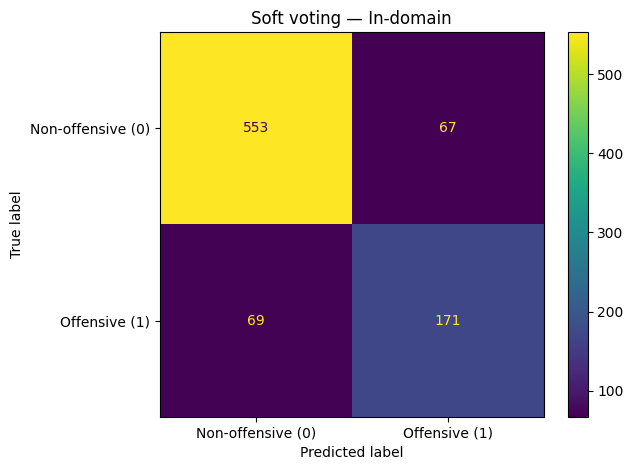

,model,setting,accuracy,macro_precision,macro_recall,macro_f1,precision_0,recall_0,f1_0,support_0,precision_1,recall_1,f1_1,support_1
0,Soft voting,In-domain,0.8419,0.8038,0.8022,0.803,0.8891,0.8919,0.8905,620,0.7185,0.7125,0.7155,240


In [34]:
metrics_in = evaluate_predictions(soft_in["labels"], soft_in["prediction"], "Soft voting", "In-domain")
display(metrics_in.round(4))

## 6. Cross-domain results

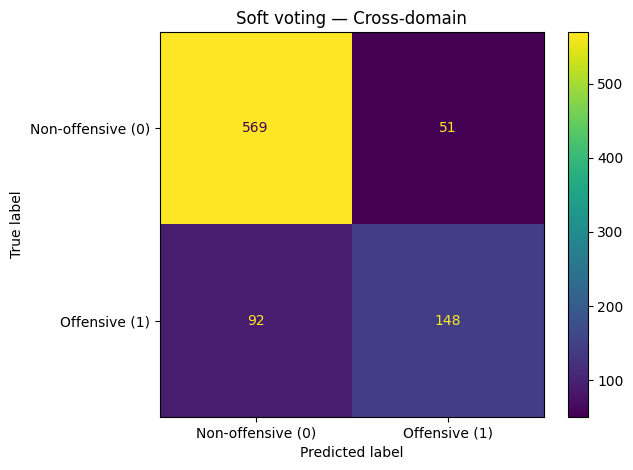

,model,setting,accuracy,macro_precision,macro_recall,macro_f1,precision_0,recall_0,f1_0,support_0,precision_1,recall_1,f1_1,support_1
0,Soft voting,Cross-domain,0.8337,0.8023,0.7672,0.7813,0.8608,0.9177,0.8884,620,0.7437,0.6167,0.6743,240


In [37]:
metrics_cross = evaluate_predictions(soft_cross["labels"], soft_cross["prediction"], "Soft voting", "Cross-domain")
display(metrics_cross.round(4))

## 7. Direct comparison and cross-domain change

In [42]:
comparison = pd.concat([metrics_in, metrics_cross], ignore_index=True)
display(comparison.round(4))
f_in = float(metrics_in.loc[0, "macro_f1"])
f_cross = float(metrics_cross.loc[0, "macro_f1"])
change = f_cross - f_in
print(f"In-domain macro-F1:     {f_in:.4f}")
print(f"Cross-domain macro-F1:  {f_cross:.4f}")
print(f"Cross minus in-domain:  {change:+.4f}")
print(f"Relative change:        {100 * change / f_in:+.2f}%")

,model,setting,accuracy,macro_precision,macro_recall,macro_f1,precision_0,recall_0,f1_0,support_0,precision_1,recall_1,f1_1,support_1
0,Soft voting,In-domain,0.8419,0.8038,0.8022,0.8030,0.8891,0.8919,0.8905,620,0.7185,0.7125,0.7155,240
1,Soft voting,Cross-domain,0.8337,0.8023,0.7672,0.7813,0.8608,0.9177,0.8884,620,0.7437,0.6167,0.6743,240


In-domain macro-F1:     0.8030
Cross-domain macro-F1:  0.7813
Cross minus in-domain:  -0.0217
Relative change:        -2.70%


## 8. Comparison with the individual models


In [53]:
individual_rows = []
for suffix, setting in [("in", "In-domain"), ("cross", "Cross-domain")]:
    for model in ("bert", "hatebert", "fbert"):
        frame = data[f"{model}_{suffix}"]
        pred = (frame["probability_offensive"] >= 0.5).astype(int)
        score = evaluate_predictions(frame["labels"], pred, model, setting, show_matrix=False)
        individual_rows.append(score)
individual_metrics = pd.concat(individual_rows, ignore_index=True)
model_comparison = pd.concat([individual_metrics, comparison], ignore_index=True)
display(model_comparison[["model", "setting", "accuracy", "macro_precision", "macro_recall", "macro_f1"]].round(4))


,model,setting,accuracy,macro_precision,macro_recall,macro_f1
0,bert,In-domain,0.8233,0.7800,0.7842,0.7820
1,hatebert,In-domain,0.8407,0.8022,0.8014,0.8018
2,fbert,In-domain,0.8407,0.8014,0.8052,0.8033
3,bert,Cross-domain,0.7802,0.7264,0.7186,0.7222
4,hatebert,Cross-domain,0.8035,0.7560,0.7513,0.7536
5,fbert,Cross-domain,0.8547,0.8317,0.7932,0.8088
6,Soft voting,In-domain,0.8419,0.8038,0.8022,0.8030
7,Soft voting,Cross-domain,0.8337,0.8023,0.7672,0.7813


## 9. Interpretation
Soft voting achieved an accuracy of 0.8419 and a macro F1 of 0.8030 in the in-domain setting. It had the highest accuracy among the four methods, although its macro F1 was slightly lower than fBERT (0.8033).

In the cross-domain setting, soft voting achieved an accuracy of 0.8337 and a macro F1 of 0.7813. This was better than BERT and HateBERT, but worse than fBERT, which achieved a macro F1 of 0.8088.

These results suggest that combining model probabilities can improve overall performance, but it does not always outperform the best individual model. Equal-weight soft voting gives the same importance to all three models, even when their performance differs.

## 10. Save files for final group integration

In [56]:
out = Path(".")
soft_in.to_csv(out / "results_soft_voting_in_domain.csv", index=False)
soft_cross.to_csv(out / "results_soft_voting_cross_domain.csv", index=False)
metrics_in.to_csv(out / "metrics_soft_voting_in_domain.csv", index=False)
metrics_cross.to_csv(out / "metrics_soft_voting_cross_domain.csv", index=False)
comparison.to_csv(out / "metrics_soft_voting_comparison.csv", index=False)
model_comparison.to_csv(out / "metrics_soft_voting_vs_individual.csv", index=False)
print("Saved soft-voting results and metric CSV files.")

Saved soft-voting results and metric CSV files.


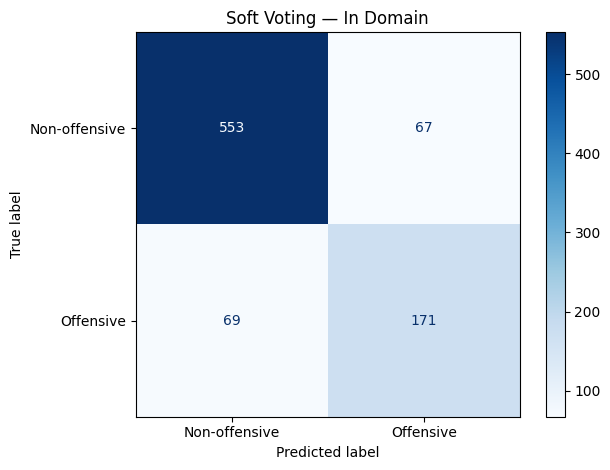

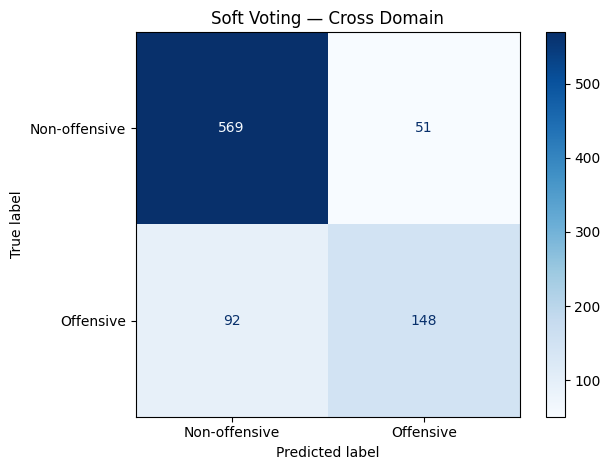

Confusion matrix images saved.


In [58]:
from pathlib import Path
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

# Create output folder
pics = Path("pics")
pics.mkdir(exist_ok=True)

for name, df in [
    ("in_domain", soft_in),
    ("cross_domain", soft_cross)
]:
    cm = confusion_matrix(
        df["labels"],
        df["prediction"],
        labels=[0, 1]
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Non-offensive", "Offensive"]
    )

    disp.plot(cmap="Blues", values_format="d")
    plt.title(f"Soft Voting — {name.replace('_', ' ').title()}")
    plt.tight_layout()

    plt.savefig(
        pics / f"confusion_soft_voting_{name}.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

print("Confusion matrix images saved.")